Task 2.3

In [10]:
import time
import numpy as np
import matplotlib.pyplot as plt

In [11]:
# 1) Моделирование с циклами
def simulate_event_loop(det, pos, N_photons):
    directions = []
    for i in range(N_photons):
        phi = np.random.uniform(0, 2 * np.pi)
        U = np.random.uniform(-1, 1)
        sin_theta = np.sqrt(1 - U**2)

        x = sin_theta * np.cos(phi)
        y = sin_theta * np.sin(phi)
        z = U
        directions.append([x, y, z])

    Q = 0
    c = np.dot(pos, pos) - det.R**2

    for direction in directions:
        direction = np.array(direction)
        b = np.dot(pos, direction)
        L = -b + np.sqrt(b**2 - c)
        pt = pos + L * direction

        for fmt in det.fmt_positions:
            d = fmt - pt
            if np.dot(d, d) <= det.r**2:
                if np.random.random() < np.exp(-L / det.lambda_zat):
                    Q += np.random.poisson(det.a)
                break

    return Q

In [12]:
# 2) Детектор и векторизация
class Detector:
    def __init__(self, R=2.0, N=40, r=0.1, a=0.5, lambda_zat=8.0):
        self.R = R
        self.N = N
        self.r = r
        self.a = a
        self.lambda_zat = lambda_zat
        self.fmt_positions = self.generate_fmts()

    def generate_fmts(self):
        phi = np.random.uniform(0, 2 * np.pi, self.N)
        U = np.random.uniform(-1, 1, self.N)
        sin_theta = np.sqrt(1 - U**2)

        x = self.R * sin_theta * np.cos(phi)
        y = self.R * sin_theta * np.sin(phi)
        z = self.R * U
        return np.column_stack([x, y, z])

    def propagate_and_detect(self, pos, directions):
        b = directions @ pos
        c = np.dot(pos, pos) - self.R**2
        L = -b + np.sqrt(b**2 - c)
        pts = pos + L[:, None] * directions

        d = pts[:, None, :] - self.fmt_positions[None, :, :]
        dist_sq = np.sum(d**2, axis=2)
        mask = np.any(dist_sq <= self.r**2, axis=1)

        p = np.exp(-L[mask] / self.lambda_zat)
        N_hit = np.sum(np.random.random(len(p)) < p)
        return np.random.poisson(N_hit * self.a)

In [13]:
# 3) Источник и генерация фотонов
class Source:
    def __init__(self, Y=10000, pos=(0.0, 0.0, 0.0)):
        self.Y = Y
        self.pos = np.array(pos, dtype=float)

    def generate_photons(self, E, N_photons=None):
        if N_photons is None:
            N_photons = np.random.poisson(self.Y * E)

        phi = np.random.uniform(0, 2 * np.pi, N_photons)
        U = np.random.uniform(-1, 1, N_photons)
        sin_theta = np.sqrt(1 - U**2)

        x = sin_theta * np.cos(phi)
        y = sin_theta * np.sin(phi)
        z = U
        return np.column_stack([x, y, z])

In [14]:
# 4) Параметры
np.random.seed(42)

R = 2.0
N = 40
r = 0.1
a = 0.5
lambda_zat = 8.0
Y = 10000
E = 1.0
N_events = 10

det = Detector(R, N, r, a, lambda_zat)
source = Source(Y, pos=(0.0, 0.0, 0.0))

# Для двух способов одинаковое число фотонов
N_vals = np.random.poisson(Y * E, N_events)

In [15]:
# 5) Моделирование с циклами
Q_loop = np.zeros(N_events, dtype=int)

t0 = time.perf_counter()
for i, n in enumerate(N_vals):
    Q_loop[i] = simulate_event_loop(det, source.pos, int(n))
t_loop = time.perf_counter() - t0

In [16]:
# 6) Моделирование с NumPy
Q_numpy = np.zeros(N_events, dtype=int)

t0 = time.perf_counter()
for i, n in enumerate(N_vals):
    directions = source.generate_photons(E, int(n))
    Q_numpy[i] = det.propagate_and_detect(source.pos, directions)
t_numpy = time.perf_counter() - t0

In [17]:
# 7) Сравнение результатов
k = t_loop / t_numpy

print(f"Время с циклами: {t_loop:.3f} с")
print(f"Время с NumPy: {t_numpy:.3f} с")
print(f"Ускорение: {k:.1f} раз")
print(f"Средний заряд с циклами: {np.mean(Q_loop):.2f}")
print(f"Средний заряд с NumPy: {np.mean(Q_numpy):.2f}")

Время с циклами: 5.658 с
Время с NumPy: 0.181 с
Ускорение: 31.3 раз
Средний заряд с циклами: 91.70
Средний заряд с NumPy: 96.10


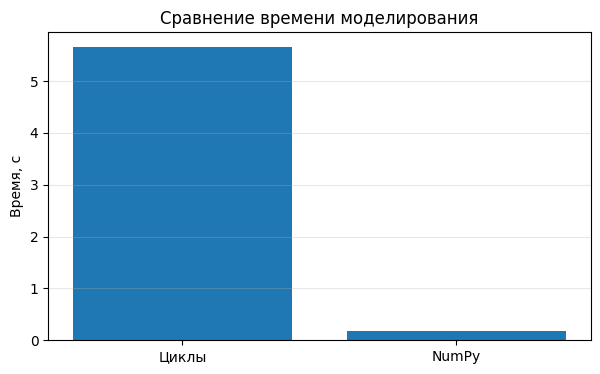

In [18]:
# 8) Сравнение времени
plt.figure(figsize=(7, 4))
plt.bar(['Циклы', 'NumPy'], [t_loop, t_numpy])
plt.ylabel('Время, с')
plt.title('Сравнение времени моделирования')
plt.grid(True, axis='y', alpha=0.3)
plt.show()